<a href="https://colab.research.google.com/github/baxodirabdugafforov7newuu/MP_Final_project/blob/main/Copy_of_Lab10_Object_Detection2_(3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 10: Object Detection II: Faster R-CNN and Single-Stage Detectors - SSD, YOLO
**CS 412: Deep Learning**

In Lab 9, R-CNN and Fast R-CNN took their region proposals from **selective search**: a fixed algorithm that runs on the CPU, learns nothing from data and was the slowest step of the detector. This lab first makes the proposals **learnable** (Faster R-CNN), then removes the proposal step altogether (**single-stage** detectors: SSD and YOLO). A detector learns from many labelled images, so both kinds are **trained on the same 1,000 images**: you will watch the losses go down and compare the results.

| Part | Topic | Time |
|---|---|---|
| 0 | Setup and the banana dataset | 2 min |
| 1 | Faster R-CNN: anchor boxes, the two stages, training on 1,000 images | 12 min |
| 2 | Why skip the region proposals? Multiscale anchors and SSD | 4 min |
| 3 | YOLO: one prediction per cell, then NMS | 4 min |
| 4 | Fine-tuning YOLO26, comparing it with Faster R-CNN, which detector when? | 6 min |
| 5–6 | Summary and tasks | 2 min |

**Tasks:** Tasks 1 and 2 are done **in class**; Tasks 3, 4 and 5 are **homework**.

**Reading:** D2L [14.4 Anchor Boxes](https://d2l.ai/chapter_computer-vision/anchor.html), [14.5 Multiscale Object Detection](https://d2l.ai/chapter_computer-vision/multiscale-object-detection.html), [14.6 The Object Detection Dataset](https://d2l.ai/chapter_computer-vision/object-detection-dataset.html), [14.7 Single Shot Multibox Detection](https://d2l.ai/chapter_computer-vision/ssd.html), [14.8.3 Faster R-CNN](https://d2l.ai/chapter_computer-vision/rcnn.html).

**Before you start:** in Colab, open *Runtime → Change runtime type* and choose a **GPU** (for example T4).

# 0. Setup

In [1]:
!pip install -q "ultralytics==8.4.198"      # pinned: YOLO26 defaults (e.g. `nms`) change between releases

In [2]:
import os, time, zipfile, shutil, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torchvision
import torchvision.transforms.functional as TF
from PIL import Image
from IPython.display import display
from ultralytics import YOLO

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def download(url, fname):
    if not os.path.exists(fname):
        urllib.request.urlretrieve(url, fname)
    return fname

download("https://raw.githubusercontent.com/d2l-ai/d2l-en/master/img/catdog.jpg", "catdog.jpg")
download("https://raw.githubusercontent.com/ultralytics/ultralytics/main/ultralytics/assets/bus.jpg", "bus.jpg")
img = Image.open("catdog.jpg").convert("RGB")
bus = Image.open("bus.jpg").convert("RGB")
w, h = img.size
gt_boxes = torch.tensor([[219.0, 280.5, 318.0, 471.0],    # dog: (cx, cy, w, h)
                         [527.5, 302.5, 255.0, 381.0]])   # cat

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
device: cuda


**Tools from Lab 9.** The functions below are the ones from Lab 9 (drawing, IoU, NMS, timing), unchanged. As in Lab 9, every box is **(cx, cy, w, h)**.

In [3]:
# torchvision describes a box by its left, top, right and bottom edges; these two helpers are used only
# where we pass boxes to torchvision or read boxes from it.
def box_center_to_corner(boxes):
    cx, cy, bw, bh = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    return torch.stack((cx - bw / 2, cy - bh / 2, cx + bw / 2, cy + bh / 2), dim=-1)

def box_corner_to_center(boxes):
    x1, y1, x2, y2 = boxes[:, 0], boxes[:, 1], boxes[:, 2], boxes[:, 3]
    return torch.stack(((x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1), dim=-1)

def show_bboxes(ax, bboxes, labels=None, colors=("b", "g", "r", "m", "c"), linestyle="-", linewidth=2):
    # Draw (cx, cy, w, h) boxes in pixels, with optional labels.
    for i, b in enumerate(bboxes):
        cx, cy, bw, bh = [float(v) for v in b]
        color = colors[i % len(colors)]
        left, top = cx - bw / 2, cy - bh / 2                  # matplotlib draws a rectangle from its upper-left point
        ax.add_patch(plt.Rectangle((left, top), bw, bh, fill=False, edgecolor=color,
                                   linewidth=linewidth, linestyle=linestyle))
        if labels:
            ax.text(left, top, labels[i], color="k" if color in ("w", "y") else "w", fontsize=9,
                    bbox=dict(facecolor=color, lw=0))

def box_iou(boxes1, boxes2):
    area = lambda b: b[:, 2] * b[:, 3]
    half1, half2 = boxes1[:, None, 2:] / 2, boxes2[:, 2:] / 2
    upper_left = torch.max(boxes1[:, None, :2] - half1, boxes2[:, :2] - half2)
    lower_right = torch.min(boxes1[:, None, :2] + half1, boxes2[:, :2] + half2)
    inter = (lower_right - upper_left).clamp(min=0).prod(dim=2)
    return inter / (area(boxes1)[:, None] + area(boxes2) - inter)

def nms(boxes, scores, iou_threshold):
    order = torch.argsort(scores, descending=True)
    keep = []
    while order.numel() > 0:
        best = order[0]
        keep.append(int(best))
        ious = box_iou(boxes[best][None], boxes[order[1:]])[0]
        order = order[1:][ious <= iou_threshold]
    return torch.tensor(keep, dtype=torch.long)

def time_ms(fn, repeats=10):
    fn()                                                   # warm-up
    if device.type == "cuda": torch.cuda.synchronize()
    t0 = time.perf_counter()
    for _ in range(repeats): fn()
    if device.type == "cuda": torch.cuda.synchronize()
    return 1000 * (time.perf_counter() - t0) / repeats

**The banana dataset (D2L 14.6).** Both detectors in this lab are trained on D2L's banana dataset: **1,000 training** and **100 validation** images (256 × 256), each with one banana pasted on a background. `label.csv` gives `img_name, label, xmin, ymin, xmax, ymax`, the left, top, right and bottom edges of the box in pixels; `label_box` turns them into our (cx, cy, w, h).

1000 training and 100 validation images, size (256, 256)


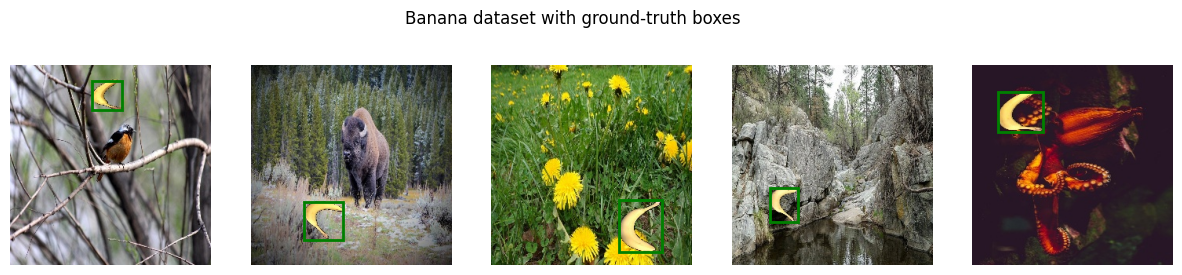

In [4]:
DATA_DIR = "banana-detection"
download("http://d2l-data.s3-accelerate.amazonaws.com/banana-detection.zip", "banana-detection.zip")
if not os.path.exists(DATA_DIR):
    zipfile.ZipFile("banana-detection.zip").extractall(".")

def label_box(row):
    # One row of label.csv (left, top, right and bottom edges) -> (1, 4) box (cx, cy, w, h) in pixels.
    return torch.tensor([[(row.xmin + row.xmax) / 2, (row.ymin + row.ymax) / 2, row.xmax - row.xmin,
                          row.ymax - row.ymin]], dtype=torch.float32)

def load_split(split):
    # All images of one split (RGB) and their ground-truth boxes.
    df = pd.read_csv(os.path.join(DATA_DIR, split, "label.csv"))
    imgs = [Image.open(os.path.join(DATA_DIR, split, "images", f)).convert("RGB") for f in df.img_name]
    return df, imgs, [label_box(row) for row in df.itertuples()]

train_df, train_imgs, train_gts = load_split("bananas_train")
val_df, val_imgs, val_gts = load_split("bananas_val")
print(f"{len(train_imgs)} training and {len(val_imgs)} validation images, size {train_imgs[0].size}")

fig, axes = plt.subplots(1, 5, figsize=(15, 3.2))
for ax, pil, gt in zip(axes, train_imgs, train_gts):
    ax.imshow(pil); show_bboxes(ax, gt, colors=("g",)); ax.axis("off")
plt.suptitle("Banana dataset with ground-truth boxes"); plt.show()

# 1. Faster R-CNN: learning the region proposals (D2L 14.8.3)
Fast R-CNN (Lab 9) runs the CNN only once per image, which leaves **selective search** as the slowest step. Selective search has a second problem: it is a fixed algorithm, so it cannot get better with more training data. **Faster R-CNN** (Ren et al., 2015) replaces it with a small network, the **region proposal network (RPN)**, that works on the same feature map as the rest of the detector and is trained together with it. The RPN is built on **anchor boxes**.

## 1.1 Anchor boxes (D2L 14.4)
An **anchor box** is a fixed box centred at a pixel, with a size s (a fraction of the image) and an aspect ratio r = width / height. With sizes s₁, …, sₙ and ratios r₁, …, rₘ, D2L uses only the n + m − 1 combinations that contain s₁ or r₁, so the number per pixel stays small. `multibox_prior` returns the anchors as (cx, cy, w, h) divided by the image width and height.

Each anchor gets a training label from its IoU with the ground truth (the RPN's rule): **IoU ≥ 0.7 → object**, **IoU < 0.3 → background**, in between → ignored (no loss). In addition, every object labels its best anchor as an object, so no object is left without one.

728 x 561 image, 5 anchors per pixel: 2,042,040 anchors


,IoU dog,IoU cat,RPN label
"s=0.75, r=1",0.68,0.08,object
"s=0.5, r=1",0.49,0.00,ignored
"s=0.25, r=1",0.13,0.00,background
"s=0.75, r=2",0.41,0.18,object
"s=0.75, r=0.5",0.66,0.00,ignored


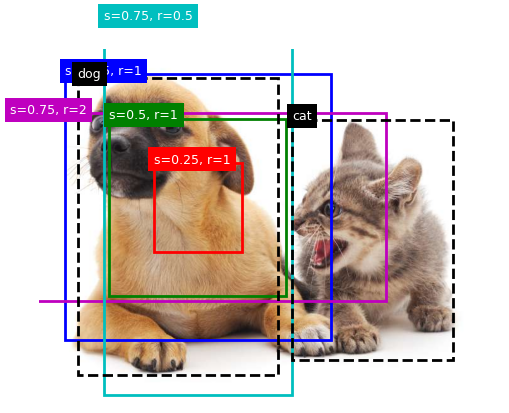

In [5]:
def multibox_prior(data, sizes, ratios):
    # Anchors centred on every pixel of data: (1, height * width * (n + m - 1), 4),
    # (cx, cy, w, h) divided by the image width and height.
    in_height, in_width = data.shape[-2:]
    boxes_per_pixel = len(sizes) + len(ratios) - 1
    size_t, ratio_t = torch.tensor(sizes, dtype=torch.float32), torch.tensor(ratios, dtype=torch.float32)
    center_h = (torch.arange(in_height) + 0.5) / in_height
    center_w = (torch.arange(in_width) + 0.5) / in_width
    shift_y, shift_x = torch.meshgrid(center_h, center_w, indexing="ij")
    shift_y, shift_x = shift_y.reshape(-1), shift_x.reshape(-1)
    aw = torch.cat((size_t * torch.sqrt(ratio_t[0]), sizes[0] * torch.sqrt(ratio_t[1:]))) * in_height / in_width
    ah = torch.cat((size_t / torch.sqrt(ratio_t[0]), sizes[0] / torch.sqrt(ratio_t[1:])))
    centers = torch.stack([shift_x, shift_y], dim=1).repeat_interleave(boxes_per_pixel, dim=0)   # every anchor's center
    wh = torch.stack([aw, ah], dim=1).repeat(in_height * in_width, 1)                         # its width and height
    return torch.cat([centers, wh], dim=1).unsqueeze(0)

def label_anchors(anchors, gt, pos=0.7, neg=0.3):
    # RPN training labels: 1 object, 0 background, -1 ignored.
    best_iou = box_iou(anchors, gt).max(dim=1).values
    labels = torch.full((len(anchors),), -1)
    labels[best_iou < neg] = 0
    labels[best_iou >= pos] = 1
    labels[box_iou(anchors, gt).argmax(dim=0)] = 1     # every object gets at least its best anchor
    return labels

anchors = multibox_prior(torch.zeros((1, 3, h, w)), sizes=[0.75, 0.5, 0.25], ratios=[1, 2, 0.5])
print(f"{w} x {h} image, 5 anchors per pixel: {anchors.shape[1]:,} anchors")

anchors_250 = anchors.reshape(h, w, 5, 4)[250, 250] * torch.tensor([w, h, w, h])   # the 5 anchors at pixel (250, 250)
anchor_names = ["s=0.75, r=1", "s=0.5, r=1", "s=0.25, r=1", "s=0.75, r=2", "s=0.75, r=0.5"]
table = pd.DataFrame(box_iou(anchors_250, gt_boxes).numpy().round(2), index=anchor_names, columns=["IoU dog", "IoU cat"])
table["RPN label"] = [{1: "object", 0: "background", -1: "ignored"}[l] for l in label_anchors(anchors_250, gt_boxes).tolist()]
display(table)
fig, ax = plt.subplots(figsize=(6, 4.6))
ax.imshow(img); show_bboxes(ax, anchors_250, anchor_names)
show_bboxes(ax, gt_boxes, ["dog", "cat"], colors=("k",), linestyle="--"); ax.axis("off"); plt.show()

Here only 5 anchors at one pixel are compared and none reaches IoU 0.7, so both objects get an *object* anchor only from the extra rule; the cat's best anchor (IoU 0.18) fits it badly. Anchors on **every pixel** give over 2 million anchors for this small photo, far too many. The RPN therefore places anchors only at the cells of the backbone's **feature map**, a much coarser grid.

## 1.2 The two stages
- **Stage 1, the RPN:** a 3 × 3 CONV layer slides over the feature map. For every anchor at every cell it predicts an **objectness** score (object or background, no class yet) and 4 **offsets** that turn the anchor into a proposal (the offsets of Lab 9, Part 3.2). NMS (threshold 0.7) then keeps the best ~1,000 proposals.
- **Stage 2, the Fast R-CNN head from Lab 9:** **RoI pooling** of every proposal, then the **classes + background** and 4 offsets that refine the box.

Both stages share the backbone and are trained together, with four losses:

| stage | loss (torchvision name) | question it answers |
|---|---|---|
| 1 (RPN) | `loss_objectness` (cross-entropy) | is there an object at this anchor? |
| 1 (RPN) | `loss_rpn_box_reg` (smooth L1) | how must the anchor move to cover the object? |
| 2 | `loss_classifier` (cross-entropy) | which class is the proposal (or background)? |
| 2 | `loss_box_reg` (smooth L1) | how must the proposal move to fit the object? |

The next cell runs torchvision's Faster R-CNN, pretrained on COCO (80 classes; backbone ResNet-50 from Lab 6 with a *feature pyramid* of 5 feature maps), on `bus.jpg`. It shows the proposals of stage 1 next to the final detections of stage 2, and times the shared **backbone**, **stage 1** and **stage 2**.

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth" to /root/.cache/torch/hub/checkpoints/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth


100%|██████████| 167M/167M [00:00<00:00, 177MB/s]


stage 1 scores 217,413 anchors and keeps 1000 proposals


,ms
backbone (shared),68.9
stage 1: region proposals (RPN + NMS),32.6
stage 2: RoI pooling + classifier on 1000 proposals,42.4


whole Faster R-CNN (with resizing): 153 ms per image


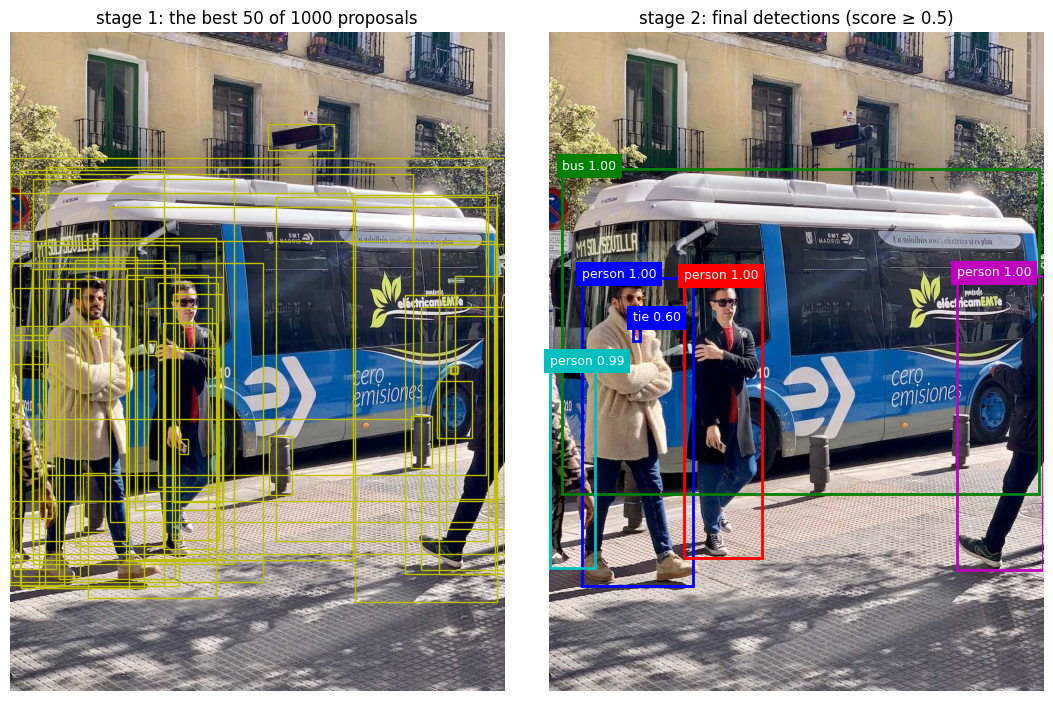

In [6]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights

frcnn_weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT
frcnn = fasterrcnn_resnet50_fpn_v2(weights=frcnn_weights).to(device).eval()
coco_names = frcnn_weights.meta["categories"]

def frcnn_predict(pil_img, score_threshold=0.5):
    x = TF.to_tensor(pil_img).to(device)
    with torch.no_grad():
        out = frcnn([x])[0]
    keep = out["scores"] >= score_threshold
    boxes = box_corner_to_center(out["boxes"][keep].cpu())       # torchvision returns edges -> (cx, cy, w, h)
    return boxes, out["scores"][keep].cpu(), out["labels"][keep].cpu()

with torch.no_grad():
    images, _ = frcnn.transform([TF.to_tensor(bus).to(device)])         # resized: shorter side 800 pixels
    features = frcnn.backbone(images.tensors)                           # 5 feature maps
    proposals, _ = frcnn.rpn(images, features)
    n_anchors = 3 * sum(f.shape[-2] * f.shape[-1] for f in features.values())   # 3 aspect ratios per cell
    parts = {"backbone (shared)": time_ms(lambda: frcnn.backbone(images.tensors)),
             "stage 1: region proposals (RPN + NMS)": time_ms(lambda: frcnn.rpn(images, features)),
             f"stage 2: RoI pooling + classifier on {len(proposals[0])} proposals":
                 time_ms(lambda: frcnn.roi_heads(features, proposals, images.image_sizes))}
    rpn_props = frcnn.transform.postprocess([{"boxes": proposals[0]}], images.image_sizes,
                                            [(bus.height, bus.width)])[0]["boxes"].cpu()
    rpn_props = box_corner_to_center(rpn_props)                         # torchvision returns edges -> (cx, cy, w, h)
frcnn_ms = time_ms(lambda: frcnn_predict(bus))
print(f"stage 1 scores {n_anchors:,} anchors and keeps {len(proposals[0])} proposals")
display(pd.DataFrame({"ms": [round(v, 1) for v in parts.values()]}, index=list(parts.keys())))
print(f"whole Faster R-CNN (with resizing): {frcnn_ms:.0f} ms per image")

boxes, scores, labels = frcnn_predict(bus)
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
axes[0].imshow(bus); show_bboxes(axes[0], rpn_props[:50], colors=("y",), linewidth=1)
axes[0].set_title(f"stage 1: the best 50 of {len(rpn_props)} proposals")
axes[1].imshow(bus); show_bboxes(axes[1], boxes, [f"{coco_names[k]} {p:.2f}" for k, p in zip(labels.tolist(), scores.tolist())])
axes[1].set_title("stage 2: final detections (score ≥ 0.5)")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

The proposals of stage 1 have no class: they only say *there is probably an object here*, so many of them overlap. Stage 2 classifies every one of them and refines its box. Keep the time table in mind: Part 2 asks what we gain by removing the two stages.

## 1.3 Training Faster R-CNN on 1,000 images
A detector learns what a banana looks like, and how to fit a box around it, only from **many labelled examples**. We fine-tune the COCO model (transfer learning, Lab 6) on all 1,000 training images:
- the last layer of stage 2 is replaced by a new one for **2 classes** (0 = background, 1 = banana); it starts from random weights, everything else starts from COCO;
- one **iteration** = one mini-batch of 8 images: in train mode the model returns the **4 losses** of the table above, we add them, backpropagate and take one SGD step; one **epoch** = 125 iterations, every training image once.

To keep training short, the images stay at 256 × 256 (torchvision would enlarge them to 800 pixels) and stage 2 computes its loss on 128 proposals per image instead of 512.

epoch 1/2: mean total loss 0.273
epoch 2/2: mean total loss 0.075
250 iterations (2 epochs x 125 mini-batches) in 115 s


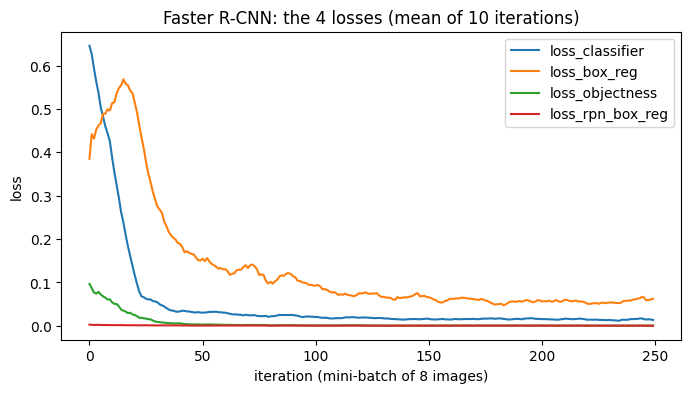

In [7]:
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor

def make_frcnn_bananas():
    # COCO-pretrained Faster R-CNN with a new last layer for 2 classes (0 = background, 1 = banana).
    model = fasterrcnn_resnet50_fpn_v2(weights=frcnn_weights, min_size=256, max_size=256,
                                       box_batch_size_per_image=128)
    in_features = model.roi_heads.box_predictor.cls_score.in_features
    model.roi_heads.box_predictor = FastRCNNPredictor(in_features, 2)          # new, random weights
    return model.to(device)

class BananaTrainSet(torch.utils.data.Dataset):
    def __len__(self):
        return len(train_imgs)
    def __getitem__(self, i):
        target = {"boxes": box_center_to_corner(train_gts[i]),                 # torchvision wants edges
                  "labels": torch.ones(len(train_gts[i]), dtype=torch.int64)}  # every box is a banana (class 1)
        return TF.to_tensor(train_imgs[i]), target

train_loader = torch.utils.data.DataLoader(BananaTrainSet(), batch_size=8, shuffle=True,
                                           collate_fn=lambda batch: tuple(zip(*batch)))   # lists of images and targets

def train_frcnn(model, epochs, lr=0.01):
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=1e-4)
    warmup = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=0.1, total_iters=50)   # small steps at first
    history, t0 = [], time.time()
    model.train()
    for epoch in range(epochs):
        for images, targets in train_loader:                                   # one mini-batch of 8 images
            images = [x.to(device) for x in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]
            losses = model(images, targets)                                    # train mode: dict with the 4 losses
            loss = sum(losses.values())
            optimizer.zero_grad(); loss.backward(); optimizer.step(); warmup.step()
            history.append({k: v.item() for k, v in losses.items()})
        epoch_loss = pd.DataFrame(history[-len(train_loader):]).sum(axis=1).mean()
        print(f"epoch {epoch + 1}/{epochs}: mean total loss {epoch_loss:.3f}")
    model.eval()
    return pd.DataFrame(history), time.time() - t0

FRCNN_EPOCHS = 2
frcnn_bananas = make_frcnn_bananas()
frcnn_hist, frcnn_train_s = train_frcnn(frcnn_bananas, FRCNN_EPOCHS)
print(f"{len(frcnn_hist)} iterations ({FRCNN_EPOCHS} epochs x {len(train_loader)} mini-batches) in {frcnn_train_s:.0f} s")
frcnn_hist.rolling(10, min_periods=1).mean().plot(figsize=(8, 4), xlabel="iteration (mini-batch of 8 images)",
                                                 ylabel="loss", title="Faster R-CNN: the 4 losses (mean of 10 iterations)")
plt.show()

Each curve is one loss from the table in Part 1.2. Compare where they start. The RPN was already trained on COCO, so `loss_objectness` and `loss_rpn_box_reg` start close to 0. The new last layer of stage 2 gives both the class scores **and** the box offsets, and it starts from random weights, so `loss_classifier` and `loss_box_reg` start high. `loss_box_reg` even rises for the first ~20 iterations: the new layer is still random and the warm-up is still raising the learning rate. A short rise at the start is normal; what matters is that every loss goes down.

**Did it learn?** For every validation image (never used in training) we take the model's most confident box and compute its IoU with the ground truth. `best_box` and `best_box_iou` work for both Faster R-CNN and YOLO, so Part 4 reuses them.

Faster R-CNN, 100 validation images: bananas found with IoU >= 0.5: 100% | mean IoU: 0.940


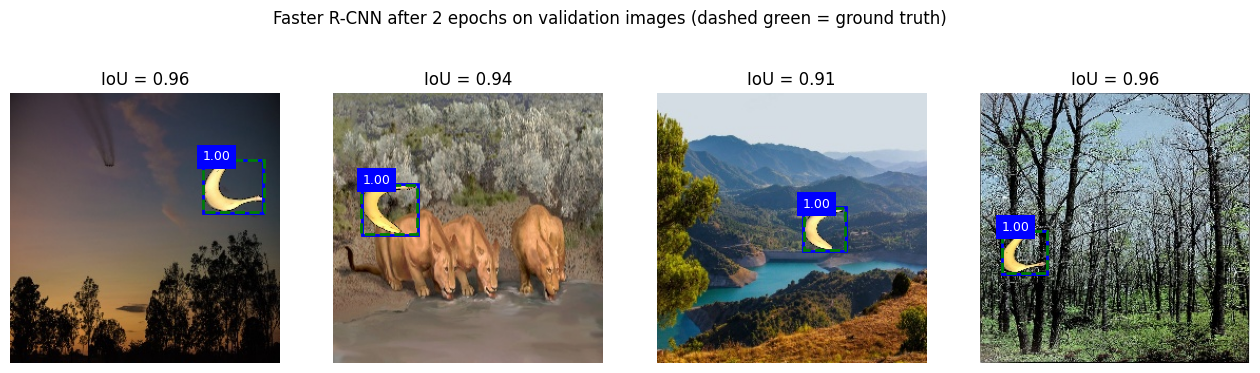

In [8]:
def best_box(model, pil, **predict_kw):
    # The model's most confident box (1, 4) as (cx, cy, w, h) and its score, or (None, 0) if it finds nothing.
    if isinstance(model, YOLO):
        r = model.predict(pil, imgsz=256, verbose=False, **predict_kw)[0]
        boxes, scores = r.boxes.xywh.cpu(), r.boxes.conf.cpu()
    else:                                                                      # torchvision Faster R-CNN
        model.eval()
        with torch.no_grad():
            out = model([TF.to_tensor(pil).to(device)])[0]
        boxes, scores = box_corner_to_center(out["boxes"].cpu()), out["scores"].cpu()   # torchvision returns edges
    if len(scores) == 0:
        return None, 0.0
    i = int(scores.argmax())
    return boxes[i:i + 1], scores[i].item()

def best_box_iou(model, **predict_kw):
    # For every validation image: IoU between the most confident box and the ground truth (0 if no box).
    ious = []
    for pil, gt in zip(val_imgs, val_gts):
        box, _ = best_box(model, pil, **predict_kw)
        ious.append(box_iou(box, gt).item() if box is not None else 0.0)
    return np.array(ious)

def show_val_predictions(model, title, n=4):
    fig, axes = plt.subplots(1, n, figsize=(4 * n, 4.5))
    for ax, pil, gt in zip(axes, val_imgs, val_gts):
        box, score = best_box(model, pil)
        ax.imshow(pil)
        if box is not None:
            show_bboxes(ax, box, [f"{score:.2f}"], colors=("b",))
            ax.set_title(f"IoU = {box_iou(box, gt).item():.2f}")
        show_bboxes(ax, gt, colors=("g",), linestyle="--")                       # ground truth on top
        ax.axis("off")
    plt.suptitle(f"{title} on validation images (dashed green = ground truth)"); plt.show()

frcnn_ious = best_box_iou(frcnn_bananas)
print(f"Faster R-CNN, {len(val_imgs)} validation images: bananas found with IoU >= 0.5: {np.mean(frcnn_ious >= 0.5):.0%}"
      f" | mean IoU: {frcnn_ious.mean():.3f}")
show_val_predictions(frcnn_bananas, f"Faster R-CNN after {FRCNN_EPOCHS} epochs")

# 2. Why skip the region proposal step?
**The cost of two stages.** In the time table of Part 1.2 the backbone is the largest part, but stage 1 and stage 2 together take about as long. A **single-stage detector** removes both: every anchor directly does the job of the *second* stage, predicting the **C classes + background** and its 4 offsets. There are no proposals, no RoI pooling and no per-proposal classifier, only one network and one forward pass, followed by NMS.

| | per anchor, the network predicts | then |
|---|---|---|
| two-stage (Faster R-CNN) | objectness (object / background) + 4 offsets | NMS → ~1,000 proposals → RoI pooling → classes + offsets |
| single-stage (SSD, YOLO) | **C classes + background** + 4 offsets | NMS → final boxes |

Two problems must be solved. Without a second look at each object, the anchors must already cover objects of **every size** (Part 2.1). And almost all anchors are **background**, so the loss must not be dominated by easy background anchors (SSD keeps only the hardest background anchors, *hard negative mining*; RetinaNet down-weights the easy ones with the *focal loss*).

## 2.1 Multiscale anchors (D2L 14.5)
Anchors on every pixel gave over 2 million anchors for one small photo (Part 1.1). Two ideas fix this:
1. place anchor centres on a **coarse grid** instead of every pixel;
2. use **small anchors on a fine grid** for small objects and **large anchors on a coarse grid** for large objects.

A CNN gives us these grids for free: each layer's **feature map** is a grid, and deeper layers have smaller feature maps whose cells see larger regions of the image.

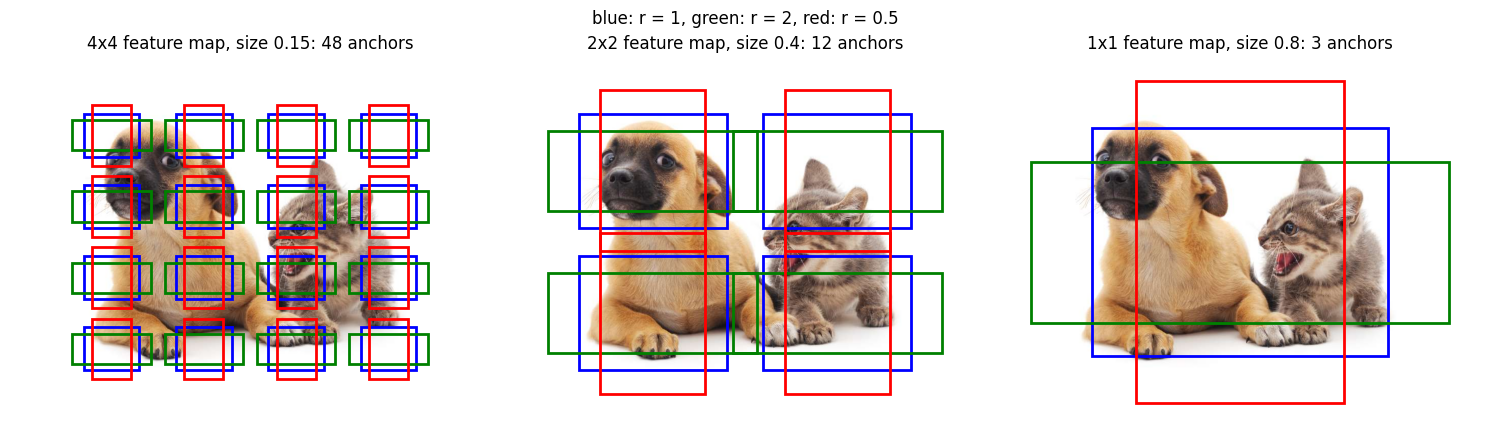

In [9]:
bbox_scale = torch.tensor((w, h, w, h))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (fmap, s) in zip(axes, [(4, 0.15), (2, 0.4), (1, 0.8)]):
    anchors = multibox_prior(torch.zeros((1, 1, fmap, fmap)), sizes=[s], ratios=[1, 2, 0.5])
    ax.imshow(img); show_bboxes(ax, anchors[0] * bbox_scale, colors=("b", "g", "r"))
    ax.set_xlim(-0.15 * w, 1.15 * w); ax.set_ylim(1.15 * h, -0.15 * h)    # anchors may leave the image
    ax.set_title(f"{fmap}x{fmap} feature map, size {s}: {anchors.shape[1]} anchors"); ax.axis("off")
plt.suptitle("blue: r = 1, green: r = 2, red: r = 0.5"); plt.tight_layout(); plt.show()

We use many small boxes at closely spaced locations for small objects, and fewer large boxes at widely spaced locations for large objects. The network then scores and adjusts these boxes.

## 2.2 SSD: single shot multibox detection (D2L 14.7)
**SSD** (Liu et al., 2016) puts these ideas into one network. For a 256 × 256 input, D2L's TinySSD:
- uses a small CNN whose feature maps are 32 × 32, 16 × 16, 8 × 8, 4 × 4 and 1 × 1;
- gives every feature map its own anchor sizes (small on the big maps, large on the small maps), 4 anchors per cell;
- at every scale, one 3 × 3 CONV layer predicts the classes (+ background) of the 4 anchors of every cell, and a second one predicts their 4 offsets (weight sharing: a banana is detected the same way wherever it is).

That is (32² + 16² + 8² + 4² + 1²) × 4 = **5,444** anchors per image, each with its final class scores and offsets, from one forward pass. Training uses the tools of Part 1.1 and Lab 9: anchor labels from IoU, cross-entropy on the classes and L1 on the offsets of non-background anchors; at prediction time NMS removes duplicates.

# 3. YOLO
## 3.1 The idea
**YOLO** ("You Only Look Once", Redmon et al., 2016) is a single-stage detector like SSD: one CNN pass over the whole image directly outputs all boxes and classes. It was the first detector fast enough for real-time video.

| Version | Year | Main change | Link to this course |
|---|---|---|---|
| YOLOv1 | 2016 | 7 × 7 grid; the cell containing an object's centre predicts its box | single-stage |
| YOLOv2 | 2017 | **anchor boxes** (sizes chosen by k-means on the training boxes) | Part 1.1 |
| YOLOv3 | 2018 | predictions at **3 scales** | Part 2.1 |
| YOLOv8 | 2023 | **anchor-free**: each feature-map cell predicts the distances from its centre to the 4 box edges | anchors without anchor boxes |
| YOLO26 | 2026 | extra **NMS-free head** that gives one box per object | Part 3.2 |

*Anchor-free* keeps the idea of anchors: the centre of each cell plays the role of the anchor, and IoU is still used to assign training targets and in the loss.

We use **YOLO26n** (n = nano, the smallest), pretrained on COCO. Its result object gives the boxes as `boxes.xywh`: (cx, cy, w, h) in pixels, the same format as ours.

,class,confidence,"box (cx, cy, w, h)"
0,dog,0.769,"[261.6, 276.6, 421.8, 469.5]"
1,cat,0.423,"[528.7, 300.2, 261.8, 369.5]"


IoU of YOLO's boxes with our ground truth (rows: YOLO boxes, columns: dog, cat):
[[      0.743       0.103]
 [          0       0.946]]

parameters: Faster R-CNN 43.7 M, YOLO26n 2.6 M


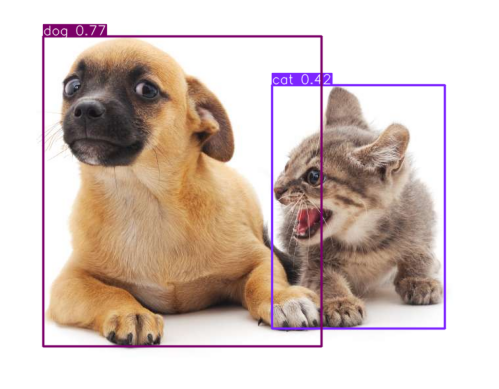

In [10]:
yolo26 = YOLO("yolo26n.pt")
res = yolo26.predict("catdog.jpg", verbose=False)[0]
display(pd.DataFrame({
    "class": [res.names[int(c)] for c in res.boxes.cls],
    "confidence": res.boxes.conf.cpu().numpy().round(3),
    "box (cx, cy, w, h)": [list(v.round(1)) for v in res.boxes.xywh.cpu().numpy()],
}))
print("IoU of YOLO's boxes with our ground truth (rows: YOLO boxes, columns: dog, cat):")
print(box_iou(res.boxes.xywh.cpu(), gt_boxes).numpy().round(3))

print(f"\nparameters: Faster R-CNN {sum(p.numel() for p in frcnn.parameters()) / 1e6:.1f} M, "
      f"YOLO26n {sum(p.numel() for p in yolo26.model.parameters()) / 1e6:.1f} M")
plt.imshow(res.plot()[..., ::-1]); plt.axis("off"); plt.show()       # plot() returns BGR

**Compare detectors of similar size.** YOLO26n has about 17 times fewer parameters than our Faster R-CNN. So when we compare their speed (Part 4), the gap has two causes: no second stage **and** a much smaller network; Task 5 separates the two with YOLO26x, whose size is similar to Faster R-CNN's. The same care is needed for accuracy: on COCO, Faster R-CNN (mAP50-95 46.7) beats YOLO26n (40.9), but Ultralytics reports 57.5 for YOLO26x (55.7 M parameters). At a similar size, today's single-stage detectors are not less accurate.

## 3.2 Inside YOLO: one prediction per cell, then NMS
Ultralytics hides the raw network output, so we call the network of **YOLO11n** (a YOLO with ordinary NMS) directly. Its head makes one prediction for **every cell** of three feature maps with strides 8, 16 and 32 (the multiscale idea of Part 2.1, without anchor boxes). Each prediction has 4 box numbers, (cx, cy, w, h) in pixels like ours, and 80 class scores. Then we remove the duplicates with **our own `nms`** from Lab 9, using Ultralytics' default IoU threshold of 0.7.

raw output: (8400, 84) | feature maps: ['80x80', '40x40', '20x20']
8400 predictions -> 51 with score > 0.25 -> 5 after our NMS (Ultralytics' own predict: 5)


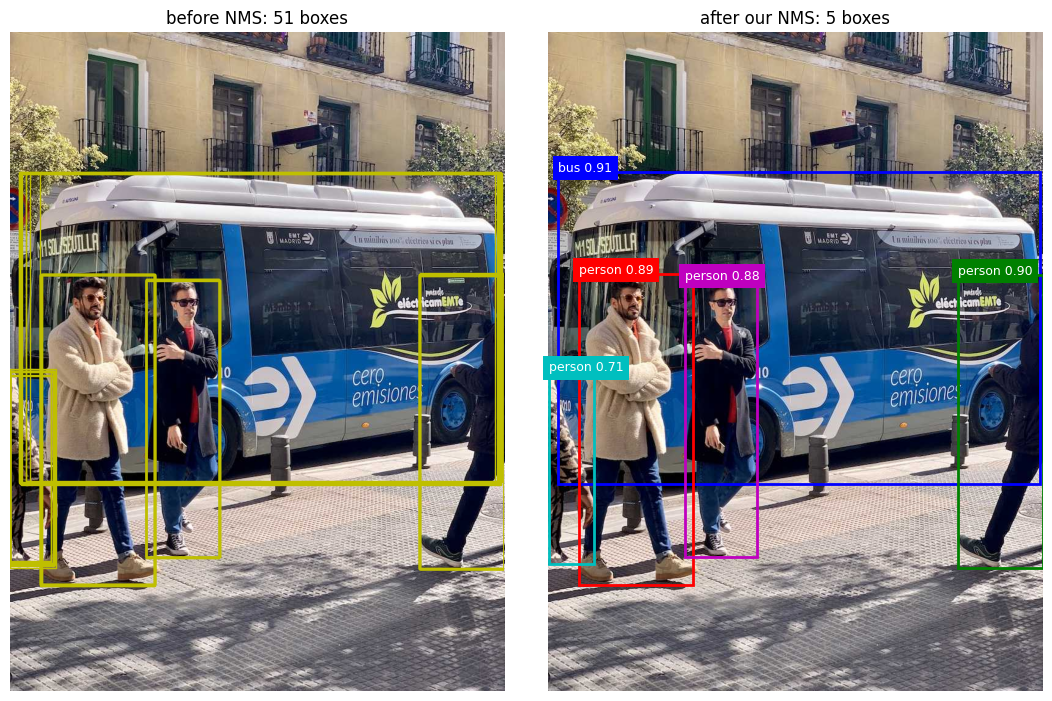

In [11]:
yolo11 = YOLO("yolo11n.pt")
net = yolo11.model.float().eval()
x = TF.to_tensor(bus.resize((640, 640)))[None]                                   # stretched to 640 x 640
with torch.no_grad():
    raw = net(x.to(next(net.parameters()).device))[0][0].T.cpu()                    # (predictions, 4 + 80)
print("raw output:", tuple(raw.shape), "| feature maps:", [f"{640 // int(st)}x{640 // int(st)}" for st in net.stride])

conf, cls = raw[:, 4:].max(dim=1)                    # best class score of every prediction
cand = conf > 0.25                                   # Ultralytics' default confidence threshold
cand_boxes = raw[cand, :4] * torch.tensor([bus.width / 640, bus.height / 640] * 2)    # back to the photo's size
keep = nms(cand_boxes, conf[cand], 0.7)
print(f"{len(raw)} predictions -> {int(cand.sum())} with score > 0.25 -> {len(keep)} after our NMS "
      f"(Ultralytics' own predict: {len(yolo11.predict(bus, verbose=False)[0].boxes)})")

names = [f"{yolo11.names[int(c)]} {p:.2f}" for c, p in zip(cls[cand][keep], conf[cand][keep])]
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
axes[0].imshow(bus); show_bboxes(axes[0], cand_boxes, colors=("y",), linewidth=1)   # thin: many boxes lie on top of each other
axes[0].set_title(f"before NMS: {int(cand.sum())} boxes")
axes[1].imshow(bus); show_bboxes(axes[1], cand_boxes[keep], names); axes[1].set_title(f"after our NMS: {len(keep)} boxes")
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.show()

On the left, many boxes lie almost exactly on top of each other: neighbouring cells, and cells of different feature maps, all predict the same person. Compare with Part 1.2: Faster R-CNN scored about 200,000 anchors in stage 1 and then ran stage 2 on 1,000 proposals; YOLO makes 8,400 predictions in one pass, and they are already final up to NMS.

**YOLO26 can skip NMS.** Besides its default head (used in this lab, with NMS, like YOLO11), YOLO26 has a second, *one-to-one* head, selected with `predict(..., nms=False)`, that is trained to give exactly one box per object, so no NMS is needed.

# 4. Fine-tuning YOLO26 on the banana dataset
YOLO wants one `.txt` file per image with one line per object: `class cx cy w h`, our (cx, cy, w, h) **divided by the image width and height** (values 0–1). As for Faster R-CNN in Part 1.3, this is **transfer learning** (Lab 6): we start from COCO weights and train on the same 1,000 images.

In [12]:
YOLO_DIR = os.path.abspath("bananas_yolo")

def convert_split(df, imgs, gts, src, dst):
    # Copy the images and write one YOLO label file per image: 'class cx cy w h', divided by the image size.
    for sub in ["images", "labels"]:
        os.makedirs(os.path.join(YOLO_DIR, sub, dst), exist_ok=True)
    for name, pil, gt in zip(df.img_name, imgs, gts):
        shutil.copy(os.path.join(DATA_DIR, src, "images", name), os.path.join(YOLO_DIR, "images", dst))
        cx, cy, bw, bh = (gt[0] / torch.tensor([pil.width, pil.height, pil.width, pil.height])).tolist()
        with open(os.path.join(YOLO_DIR, "labels", dst, os.path.splitext(name)[0] + ".txt"), "w") as f:
            f.write(f"0 {cx:.6f} {cy:.6f} {bw:.6f} {bh:.6f}\n")                 # class 0 = banana

convert_split(train_df, train_imgs, train_gts, "bananas_train", "train")
convert_split(val_df, val_imgs, val_gts, "bananas_val", "val")
with open("bananas.yaml", "w") as f:
    f.write(f"path: {YOLO_DIR}\ntrain: images/train\nval: images/val\nnames:\n  0: banana\n")

print("box of the first training image (cx, cy, w, h):", train_gts[0][0].tolist())
print("its YOLO label:", open(os.path.join(YOLO_DIR, "labels", "train",
                                           os.path.splitext(train_df.img_name[0])[0] + ".txt")).read())

box of the first training image (cx, cy, w, h): [123.5, 39.0, 39.0, 38.0]
its YOLO label: 0 0.482422 0.152344 0.152344 0.148438



**Training and evaluation.** After each epoch YOLO prints precision P, recall R, **mAP50** and **mAP50-95** on the validation images (Lab 9, Part 3.4). It also prints three losses: `box_loss` (based on IoU) and `l1_loss` (L1 on the distances to the box edges) answer *where*, `cls_loss` answers *what*: the same two questions as the four losses of Faster R-CNN. Ultralytics reads the precision–recall curve at 101 points instead of taking the exact area, so small differences mean nothing.

⚠️ Look for `Remapped 1/1 cls head rows` in the log: COCO already has a *banana* class, so Ultralytics starts our one-class head from COCO's banana weights. Task 4 measures how much this helps.

New https://pypi.org/project/ultralytics/8.4.215 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=bananas.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0

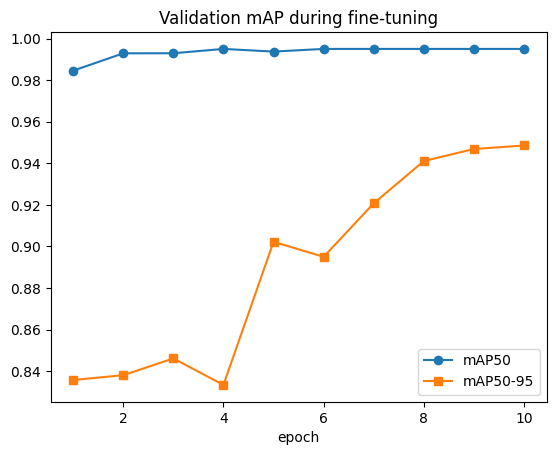

In [13]:
YOLO_EPOCHS = 10
yolo_bananas = YOLO("yolo26n.pt")
t0 = time.time()
metrics = yolo_bananas.train(data="bananas.yaml", epochs=YOLO_EPOCHS, imgsz=256, batch=32, seed=0,
                             name="bananas", exist_ok=True, plots=False, workers=2)
yolo_train_s = time.time() - t0
print(f"training time: {yolo_train_s:.0f} s")
print(f"validation: mAP50 = {metrics.box.map50:.3f}, mAP50-95 = {metrics.box.map:.3f}")

hist = pd.read_csv(os.path.join(yolo_bananas.trainer.save_dir, "results.csv"))
plt.plot(hist.epoch, hist["metrics/mAP50(B)"], "o-", label="mAP50")
plt.plot(hist.epoch, hist["metrics/mAP50-95(B)"], "s-", label="mAP50-95")
plt.xlabel("epoch"); plt.legend(); plt.title("Validation mAP during fine-tuning"); plt.show()

**Comparison with Faster R-CNN.** Both detectors started from COCO weights, were trained on the same 1,000 images with a similar time budget (about 2 minutes), and are now checked on the same 100 validation images: **accuracy** (`best_box_iou`), **size** and **speed**. Speed is the average time per image over 20 validation images at the same 256 × 256 size, including pre- and post-processing.

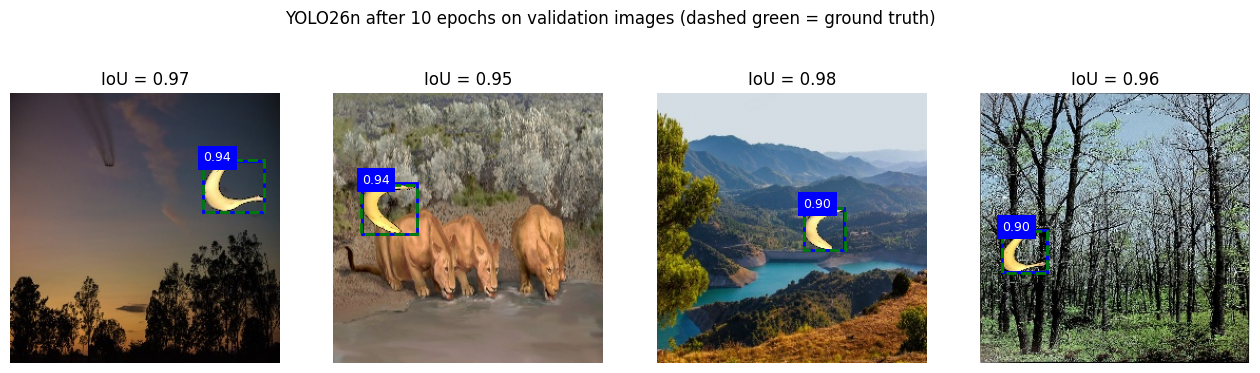

,epochs,training time (s),"found, IoU >= 0.5","found, IoU >= 0.9",mean IoU,parameters (M),ms per image
Faster R-CNN (two-stage),2,115,100%,96%,0.94,43.3,63.2
YOLO26n (single-stage),10,100,100%,96%,0.959,2.5,11.9


YOLO26n: 5.3x faster per image, 17x fewer parameters


In [14]:
yolo_ious = best_box_iou(yolo_bananas)
show_val_predictions(yolo_bananas, f"YOLO26n after {YOLO_EPOCHS} epochs")

def ms_per_image(model, n=20):
    # Average time of one prediction (pre-processing, network, post-processing) over n validation images.
    return time_ms(lambda: [best_box(model, pil) for pil in val_imgs[:n]], repeats=3) / n

rows = {}
for name, model, net, epochs, train_s, ious in [
        ("Faster R-CNN (two-stage)", frcnn_bananas, frcnn_bananas, FRCNN_EPOCHS, frcnn_train_s, frcnn_ious),
        ("YOLO26n (single-stage)", yolo_bananas, yolo_bananas.model, YOLO_EPOCHS, yolo_train_s, yolo_ious)]:
    rows[name] = {"epochs": epochs, "training time (s)": round(train_s),
                  "found, IoU >= 0.5": f"{np.mean(ious >= 0.5):.0%}", "found, IoU >= 0.9": f"{np.mean(ious >= 0.9):.0%}",
                  "mean IoU": round(ious.mean(), 3),
                  "parameters (M)": round(sum(p.numel() for p in net.parameters()) / 1e6, 1),
                  "ms per image": round(ms_per_image(model), 1)}
display(pd.DataFrame(rows).T)
frcnn_row, yolo_row = rows.values()
print(f"YOLO26n: {frcnn_row['ms per image'] / yolo_row['ms per image']:.1f}x faster per image, "
      f"{frcnn_row['parameters (M)'] / yolo_row['parameters (M)']:.0f}x fewer parameters")

**Reading the table.**
- **Accuracy:** both detectors find every banana, with almost equally tight boxes. The banana dataset is easy (one object per image, always the same kind, similar sizes), so it cannot show which design is more accurate in general.
- **Training:** both learned the task from 1,000 labelled images in about 2 minutes, starting from pretrained weights. Faster R-CNN needed fewer epochs, but each of its epochs costs much more.
- **Speed and size:** this is where they differ. YOLO26n needs less time per image and is much smaller. A video at 30 frames per second leaves 33 ms per frame for everything, and a phone or a camera has far less computing power than a T4, so when the accuracy is the same, the faster and smaller detector wins.

## 4.1 Which detector when?

| | single-stage (YOLO, SSD) | two-stage (Faster R-CNN) |
|---|---|---|
| how it works | one forward pass: every cell (or anchor) directly predicts classes + offsets | stage 1 proposes regions, stage 2 takes a **second look** at every proposal |
| speed | fast: no proposals, no RoI pooling | slower: stage 2 runs on ~1,000 proposals per image |
| accuracy | at a similar size, modern YOLOs match or beat Faster R-CNN on COCO (Part 3.1) | historically more accurate, especially for small objects and crowded scenes, thanks to the second look |
| choose it when | real-time video, phones and edge devices, many images per second; the usual default today | speed matters less than a careful look at every region, or you need the two-stage design itself, e.g. **Mask R-CNN**, which adds an object mask to stage 2 (instance segmentation) |

In practice: start with a single-stage detector, and choose a two-stage detector when its second look at each proposal (or a model built on it) is worth the extra time.

# 5. Summary
- **Faster R-CNN** replaces selective search with a learned **region proposal network**: for every **anchor box** of the feature map, stage 1 predicts *object or background* + 4 offsets; stage 2 RoI-pools the ~1,000 best proposals and predicts the classes + background and refined boxes. Both stages are trained together with **four losses** (two per stage).
- A detector is trained on **many labelled images**: one iteration = one mini-batch, losses → backpropagation → one SGD step. Starting from **pretrained weights** makes 1,000 images enough, as in Lab 6.
- **Single-stage** detectors skip the region proposal step: every anchor (or feature-map cell) directly predicts the classes + background and the box offsets, in one forward pass.
- Without proposals, the anchors must cover every object size: **multiscale** detection puts small anchors on large feature maps and large anchors on small ones (SSD: 5,444 anchors for a 256 × 256 image). Almost all anchors are background, so single-stage losses handle the imbalance (hard negative mining, focal loss).
- **YOLO** predicts once per cell of three feature maps (8,400 predictions for a 640 × 640 image) and NMS reduces them to a few boxes; YOLO26's one-to-one head skips NMS. YOLO uses the same (cx, cy, w, h) boxes as we do (`boxes.xywh`).
- On the bananas both detectors were equally accurate, but YOLO26n was faster and much smaller; Task 5 checks how much of the speed comes from skipping the second stage and how much from a smaller network.
- **Which one?** Single-stage for real-time and limited hardware (the usual default today); two-stage when a second look at every proposal, or a model built on it such as Mask R-CNN, is worth the extra time.

# 6. Tasks
**Tasks 1 and 2 are done in class. Tasks 3, 4 and 5 are homework.** Write your code in the cell under each task and give the requested numbers. Hand calculations can go in a markdown cell.

## In class

**Task 1 – Counting predictions.**

(a) YOLO11n predicts once per cell of feature maps with strides 8, 16 and 32. How many predictions does it make for a 320 × 320 and a 640 × 640 input? Check the 320 × 320 case by running `net` on a zero tensor of that size, as in Part 3.2.

(b) TinySSD (Part 2.2) uses 4 anchors per cell. For a 512 × 512 input its feature maps are 64 × 64, 32 × 32, 16 × 16, 8 × 8 and 1 × 1: how many anchors does it have? Check with `multibox_prior` (one call per feature map, on a zero tensor of shape (1, 1, k, k), with 2 sizes and the ratios [1, 2, 0.5]).

(c) For one 640 × 640 image, compare the number of class predictions made by YOLO11n with the number of proposals that Faster R-CNN's second stage classifies (Part 1.2). Why can the single-stage detector afford so many more?

In [15]:
# Task 1: your code here

**Task 2 – Precision and recall vs the confidence threshold.** Use your two trained detectors, `frcnn_bananas` and `yolo_bananas`, on the 100 validation images (one banana per image). For every image, get **all** boxes with their scores: for YOLO, `yolo_bananas.predict(pil, imgsz=256, conf=0.01, verbose=False)[0]` gives `r.boxes.xywh` and `r.boxes.conf`; for Faster R-CNN, copy the `else` branch of `best_box`.

(a) For both detectors and the thresholds 0.05, 0.5, 0.9 and 0.95: keep only the boxes with score ≥ the threshold, count them, and count the **correct** ones (IoU ≥ 0.5 with the banana, at most one per image). Fill in one table: detector, threshold, boxes, correct, precision = correct / boxes, recall = correct / 100.

(b) At which threshold do the two detectors behave very differently? Look at the scores in the validation figures of Parts 1.3 and 4: why?

(c) You switch a working system from Faster R-CNN to YOLO and keep its confidence threshold. What can go wrong?

In [16]:
# Task 2: your code here

## Homework

**Task 3 – Which parts of Faster R-CNN must be trained?** In Part 1.3 almost the whole network was trained (torchvision keeps only the first ResNet layers frozen). Train a second model with `make_frcnn_bananas` and `train_frcnn`, same number of epochs, but this time **only the new last layer** is trained: after `make_frcnn_bananas()`, set `requires_grad = False` for every parameter except those of `model.roi_heads.box_predictor`.

(a) Plot its 4 losses next to those of Part 1.3. Which losses do not go down? Explain with the table in Part 1.2.

(b) Fill in a table for both models: trainable parameters, training time, % of validation bananas found with IoU ≥ 0.5 and ≥ 0.9, mean IoU (`best_box_iou`).

(c) Which parts of the network had to be trained to get tight boxes on bananas?

In [17]:
# Task 3: your code here

**Task 4 – How much does pretraining help, and how tight are the boxes?** Compare four models on the 100 validation images with `best_box_iou`:

(a) the COCO `yolo26` **without fine-tuning**, keeping only its banana class: `best_box_iou(yolo26, classes=[46])` (46 is the index of "banana" in `yolo26.names`);

(b) your fine-tuned `yolo_bananas`;

(c) YOLO26n trained **from scratch**: `YOLO("yolo26n.yaml")` (same architecture, random weights), same `train` settings as Part 4 but `name="bananas_scratch"`;

(d) your fine-tuned Faster R-CNN `frcnn_bananas` from Part 1.3.

Fill in a table with one row per model: % of bananas found with IoU ≥ 0.5, ≥ 0.75 and ≥ 0.9, mean IoU, and for (b) and (c) mAP50 and mAP50-95. Which IoU threshold shows the largest difference between (b) and (c)?

In [18]:
# Task 4: your code here

**Task 5 – Is single-stage faster at the same size?** In Part 3.1, Faster R-CNN was much bigger than YOLO26n. **YOLO26x** (`YOLO("yolo26x.pt")`) has a size similar to Faster R-CNN.

(a) With `time_ms`, measure the time per image on `bus.jpg` for Faster R-CNN (`frcnn_predict`), YOLO26n and YOLO26x. Faster R-CNN resizes the image to a shorter side of 800 pixels, so time YOLO26x with `imgsz=640` and `imgsz=800`.

(b) For the YOLO models, also report the `inference` time from `r.speed`.

(c) Fill in a table: model, parameters (M), ms per image, network ms. At a similar number of parameters, how many times faster is the single-stage detector? Use the time table from Part 1.2 to say how much of Faster R-CNN's time the second stage takes.

In [19]:
# Task 5: your code here